<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40


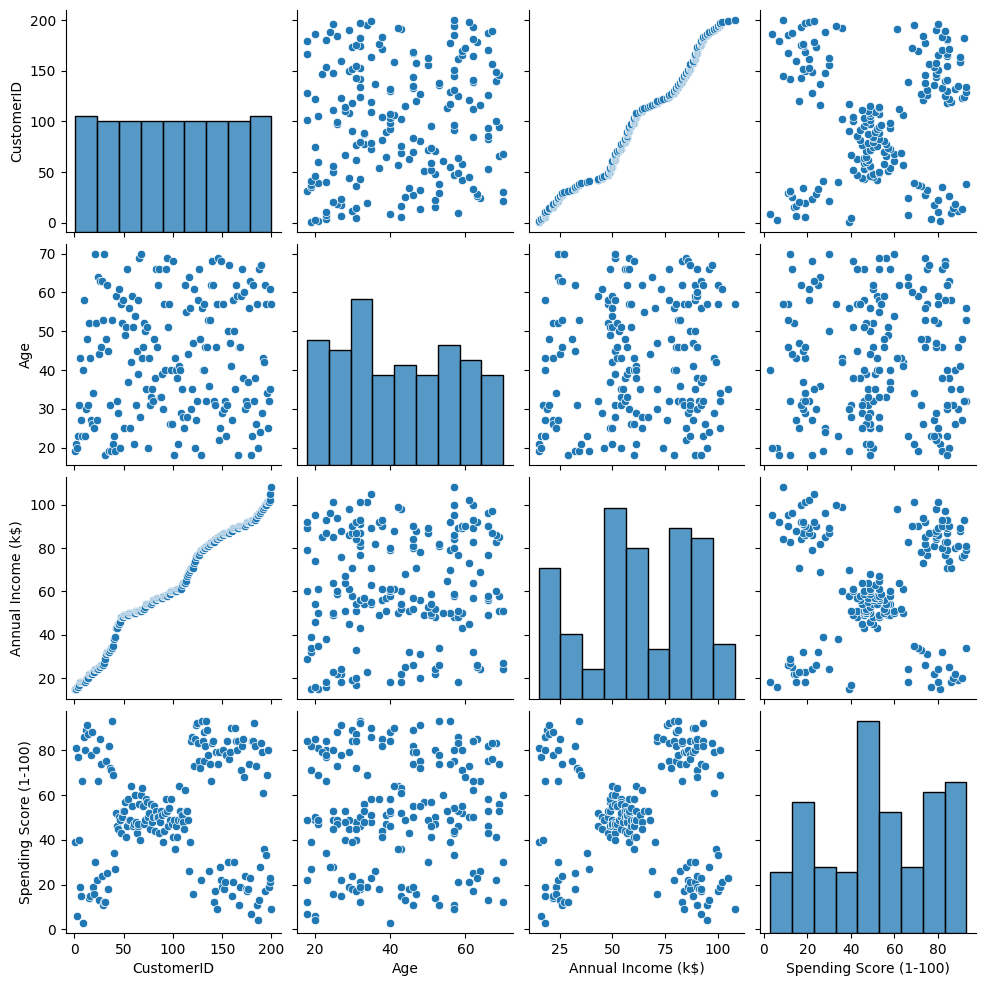

   Annual Income (k$)  Spending Score (1-100)  label
0                  15                      39      4
1                  15                      81      0
2                  16                       6      4
3                  16                      77      0
4                  17                      40      4


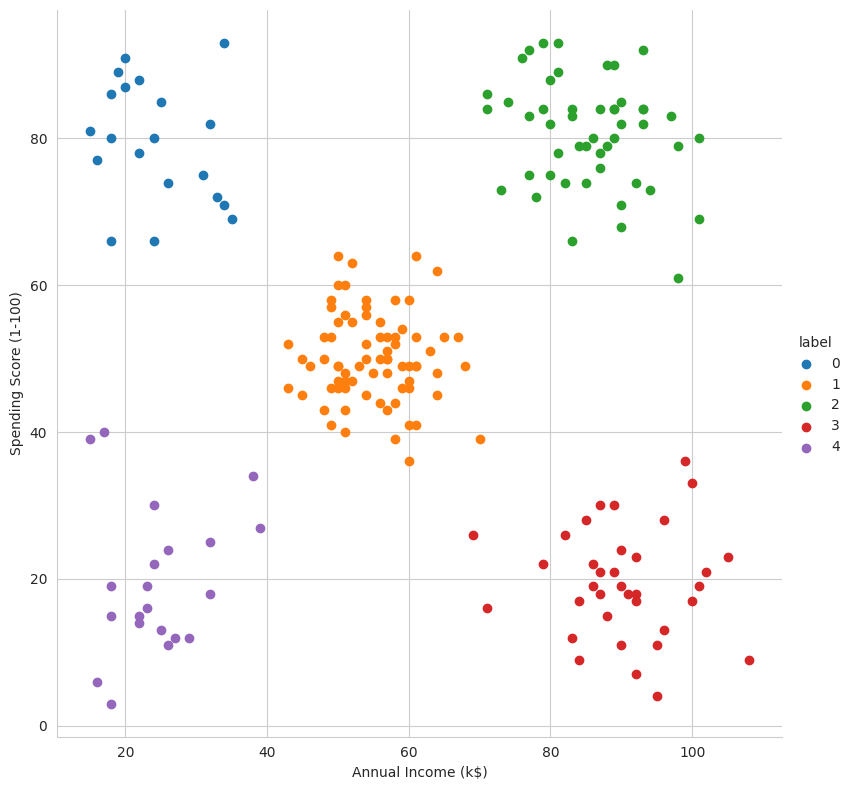

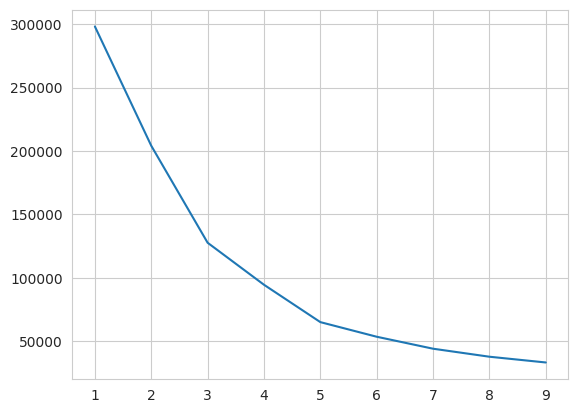

In [21]:
# 20) Experiment to understand K-means clustering algorithm for a given data set.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
# Sample Mall Customers dataset (200 records, same columns as Mall_Customers.csv)
np.random.seed(3)
head_rows = pd.DataFrame({'Gender': ['Male', 'Male', 'Female', 'Female', 'Female'],
'Age': [19, 21, 20, 23, 31],
'Annual Income (k$)': [15, 15, 16, 16, 17],
'Spending Score (1-100)': [39, 81, 6, 77, 40]})
centers = [(26, 20, 18), (26, 79, 17), (55, 50, 76), (88, 17, 35), (87, 82, 49)]
income, score = [], []
for cx, cy, size in centers:
    income += np.random.normal(cx, 7, size).tolist()
    score += np.random.normal(cy, 7, size).tolist()
gen = pd.DataFrame({'Gender': np.random.choice(['Male', 'Female'], 195),
'Age': np.random.randint(18, 71, 195),
'Annual Income (k$)': np.clip(np.round(income), 18, 137).astype(int),
'Spending Score (1-100)': np.clip(np.round(score), 1, 99).astype(int)}).sort_values('Annual Income (k$)')
df = pd.concat([head_rows, gen], ignore_index=True)
df.insert(0, 'CustomerID', range(1, 201))
df.info()
print(df.head())
# Pairplot to visualize relationships
sns.pairplot(df)
plt.show()
# Select Annual Income and Spending Score as features
features = df.iloc[:, [3, 4]].values
# Train the K-means model with 5 clusters
model = KMeans(n_clusters=5, n_init=10)
model.fit(features)
# Add the cluster label to each customer
Final = df.iloc[:, [3, 4]].copy()
Final['label'] = model.predict(features)
print(Final.head())
# Visualize the clusters
sns.set_style("whitegrid")
sns.FacetGrid(Final, hue="label", height=8) \
.map(plt.scatter, "Annual Income (k$)", "Spending Score (1-100)") \
.add_legend()
plt.show()
# Elbow method to find the optimal number of clusters
features_el = df.iloc[:, [2, 3, 4]].values
wcss = []
for i in range(1, 10):
    model = KMeans(n_clusters=i, n_init=10)
    model.fit(features_el)
    wcss.append(model.inertia_)
plt.plot(range(1, 10), wcss)
plt.show()